
# Federated Explainable Machine Learning for Privacy-Preserving Financial Fraud Detection

**Project:** PG8 – Empirical Research Mini-Project  
**Environment:** Python / Jupyter Notebook

## 1. Introduction

This project investigates the use of Federated Learning and Explainable Artificial Intelligence for financial fraud detection.

Three simulated financial institutions (Bank A, Bank B and Bank C) collaboratively train a machine-learning model without transferring their raw transaction records to a central coordinator.

Each institution independently preprocesses its local dataset using a shared feature specification. The locally trained model parameters are combined using Federated Averaging (FedAvg) to produce a global fraud-detection model.

SHAP is subsequently used to explain the model's predictions, while experimental comparisons are conducted between local, federated and centralised learning approaches.


## 2. Research Objectives

The objectives of this project are:

1. Develop a supervised machine-learning model for detecting fraudulent financial transactions.
2. Simulate three financial institutions using separate partitions of the PaySim dataset.
3. Apply consistent preprocessing rules while keeping each bank's training records separate.
4. Implement Federated Learning using the Federated Averaging (FedAvg) algorithm.
5. Evaluate and compare the local, centralised and federated models using a common held-out test dataset.
6. Apply SHAP to investigate feature importance and explain model predictions.
7. Demonstrate raw-data locality during federated training and acknowledge its privacy limitations.

In [1]:
# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import shap

## 3. Dataset Loading and Exploration
We explore the PaySim dataset to understand its structure, transaction patterns and data quality before preprocessing.

In [2]:
# Locate the PaySim dataset
from pathlib import Path

data_path = Path("../data/raw/PaySim.csv")

print("Dataset found:", data_path.exists())

Dataset found: True


In [3]:
# Load PaySim and preview the transactions
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
# Inspect the dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [12]:
# Check data quality
missing_values = df.isnull().sum()
duplicate_count = df.duplicated().sum()

print("Missing values per column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())
print("Duplicate records:", duplicate_count)


Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Total missing values: 0
Duplicate records: 0


In [13]:

# Count legitimate and fraudulent transactions
fraud_counts = df["isFraud"].value_counts().sort_index()

print("Legitimate:", fraud_counts[0])
print("Fraudulent:", fraud_counts[1])
print(f"Fraud percentage: {fraud_counts[1] / len(df):.4%}")


Legitimate: 6354407
Fraudulent: 8213
Fraud percentage: 0.1291%


In [14]:
# Examine fraud across transaction types
fraud_by_type = pd.crosstab(df["type"], df["isFraud"])
fraud_by_type.columns = ["Legitimate", "Fraudulent"]

display(fraud_by_type)

,Legitimate,Fraudulent
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [15]:
# Examine the distribution of transaction amounts
df["amount"].describe()

count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64

In [16]:
# EDA: Compare transaction amounts by fraud class
amount_by_fraud = df.groupby("isFraud")["amount"].describe()
display(amount_by_fraud.round(2))

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,178197.04,596236.98,0.01,13368.40,74684.72,208364.76,92445516.64
1,8213.0,1467967.30,2404252.95,0.00,127091.33,441423.44,1517771.48,10000000.00


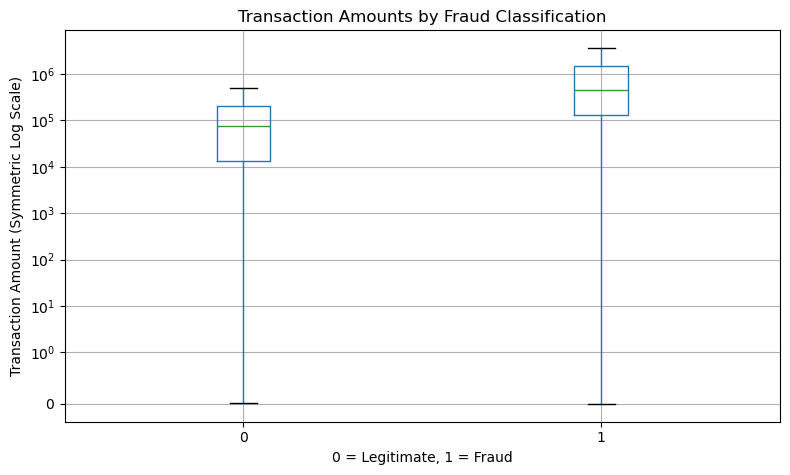

In [17]:

# EDA: Compare transaction amounts by fraud classification
df.boxplot(
    column="amount",
    by="isFraud",
    figsize=(8, 5),
    showfliers=False
)

plt.yscale("symlog", linthresh=1)
plt.title("Transaction Amounts by Fraud Classification")
plt.suptitle("")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Transaction Amount (Symmetric Log Scale)")
plt.tight_layout()
plt.show()


In [18]:
# EDA: Compare actual fraud with PaySim's existing fraud flag
fraud_flags = pd.crosstab(
    df["isFraud"],
    df["isFlaggedFraud"]
)

fraud_flags.index = ["Legitimate", "Fraudulent"]
fraud_flags.columns = ["Not Flagged", "Flagged"]

display(fraud_flags)

,Not Flagged,Flagged
Legitimate,6354407,0
Fraudulent,8197,16


In [19]:
# EDA: Inspect the PaySim simulation timeline
print("First time step:", df["step"].min())
print("Last time step:", df["step"].max())
print("Total time steps:", df["step"].nunique())

First time step: 1
Last time step: 743
Total time steps: 743


In [20]:

# EDA: Count fraudulent transactions at each time step
fraud_over_time = df.groupby("step")["isFraud"].sum()

print("Time steps containing fraud:", (fraud_over_time > 0).sum())
print("Time steps without fraud:", (fraud_over_time == 0).sum())


Time steps containing fraud: 741
Time steps without fraud: 2


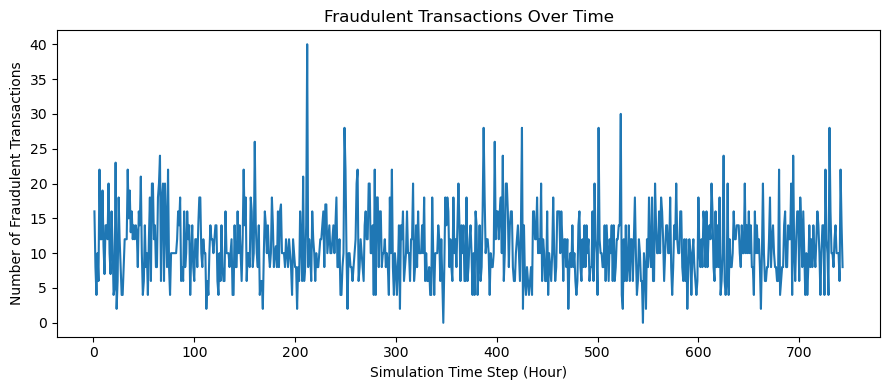

In [21]:

# EDA: Visualise fraudulent transactions over time
plt.figure(figsize=(9, 4))
plt.plot(fraud_over_time.index, fraud_over_time.values)

plt.title("Fraudulent Transactions Over Time")
plt.xlabel("Simulation Time Step (Hour)")
plt.ylabel("Number of Fraudulent Transactions")
plt.tight_layout()
plt.show()


## 4. Feature Selection

**Prediction target:** `isFraud` (0 = Legitimate, 1 = Fraudulent).

The model uses five original input features:
- `step`
- `type`
- `amount`
- `oldbalanceOrg`
- `oldbalanceDest`

**Excluded columns:**
- `nameOrig`, `nameDest`: Raw account identifiers.
- `isFlaggedFraud`: Existing fraud flag.
- `newbalanceOrig`, `newbalanceDest`: Post-transaction balances excluded to avoid potential data leakage when predicting fraud before transaction completion.

Transaction type is one-hot encoded, producing nine final numerical input features.

All three simulated banks use the same feature order and fixed preprocessing rules.

In [22]:

# Features selected for fraud prediction
FEATURE_COLUMNS = [
    "step", "type", "amount",
    "oldbalanceOrg", "oldbalanceDest"
]

TARGET_COLUMN = "isFraud"


In [23]:

# Use the same transaction categories for all banks
TRANSACTION_TYPES = [
    "CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"
]

NUMERIC_FEATURES = [
    "step", "amount", "oldbalanceOrg", "oldbalanceDest"
]

# One-hot encoding creates five transaction-type columns
ENCODED_TYPE_FEATURES = [f"type_{t}" for t in TRANSACTION_TYPES]

MODEL_INPUT_COLUMNS = NUMERIC_FEATURES + ENCODED_TYPE_FEATURES

print("Final model inputs:", MODEL_INPUT_COLUMNS)
print("Total inputs:", len(MODEL_INPUT_COLUMNS))


Final model inputs: ['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Total inputs: 9



### Shared Preprocessing Rules

All three banks apply the same preprocessing rules:

- **Numerical features:** Apply `log1p` to `step`, `amount`,
  `oldbalanceOrg` and `oldbalanceDest`.
- **Categorical feature:** Apply One-Hot Encoding to `type`
  using the five predefined transaction categories.

The `log1p` transformation reduces the effect of large values
and handles zeros without requiring shared scaling statistics.

All banks use the same nine input columns in the same order,
while keeping their raw training records separate.


In [24]:

# Verify that transactions are ordered by simulation time
assert df["step"].is_monotonic_increasing, \
    "Transactions must be sorted chronologically."

print("Chronological order verified.")


Chronological order verified.


In [25]:
# Find the hour closest to an 80/20 transaction split
# without dividing transactions from the same hour

transactions_per_step = df.groupby("step").size()
cumulative_transactions = transactions_per_step.cumsum()

target_size = len(df) * 0.80

split_step = (cumulative_transactions - target_size).abs().idxmin()

train_size = cumulative_transactions.loc[split_step]
test_size = len(df) - train_size

print("Split boundary:", split_step)
print(f"Training: {train_size:,} ({train_size / len(df):.2%})")
print(f"Testing:  {test_size:,} ({test_size / len(df):.2%})")

Split boundary: 354
Training: 5,069,097 (79.67%)
Testing:  1,293,523 (20.33%)


In [26]:
# Check fraud distribution before and after the split
fraud_per_step = df.groupby("step")["isFraud"].agg(["count", "sum"])

train_summary = fraud_per_step.loc[:split_step].sum()
test_summary = fraud_per_step.loc[split_step + 1:].sum()

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Transactions": [train_summary["count"], test_summary["count"]],
    "Fraud Cases": [train_summary["sum"], test_summary["sum"]]
})

split_summary["Fraud Rate (%)"] = (
    split_summary["Fraud Cases"] /
    split_summary["Transactions"] * 100
)

display(split_summary.round(4))

,Dataset,Transactions,Fraud Cases,Fraud Rate (%)
0,Training,5069097,3955,0.0780
1,Testing,1293523,4258,0.3292


In [27]:

# Split transactions chronologically (earlier = training, later = testing)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

print("Training:", train_df.shape, "| Hours:",
      train_df["step"].min(), "-", train_df["step"].max())

print("Testing: ", test_df.shape, "| Hours:",
      test_df["step"].min(), "-", test_df["step"].max())


Training: (5069097, 11) | Hours: 1 - 354
Testing:  (1293523, 11) | Hours: 355 - 743


In [28]:

# Verify that the chronological split is correct
assert len(train_df) + len(test_df) == len(df), "Missing transactions."
assert train_df.index.intersection(test_df.index).empty, "Overlapping records."
assert train_df["step"].max() < test_df["step"].min(), "Time overlap detected."

print("Train/test split verified successfully.")

Train/test split verified successfully.


In [29]:
# Check the training records available for bank allocation
training_counts = train_df["isFraud"].value_counts().reindex([0, 1])

print(f"Training transactions: {len(train_df):,}")
print(f"Legitimate: {training_counts[0]:,}")
print(f"Fraudulent: {training_counts[1]:,}")

Training transactions: 5,069,097
Legitimate: 5,065,142
Fraudulent: 3,955


In [30]:
# Define different class distributions for the three simulated banks
BANK_NAMES = ["Bank A", "Bank B", "Bank C"]

LEGITIMATE_SHARES = [0.50, 0.30, 0.20]
FRAUD_SHARES = [0.20, 0.30, 0.50]

# Each class must be fully allocated across the banks
assert np.isclose(sum(LEGITIMATE_SHARES), 1.0)
assert np.isclose(sum(FRAUD_SHARES), 1.0)

allocation_plan = pd.DataFrame({
    "Bank": BANK_NAMES,
    "Legitimate Share": LEGITIMATE_SHARES,
    "Fraud Share": FRAUD_SHARES
})

display(allocation_plan.style.format({
    "Legitimate Share": "{:.0%}",
    "Fraud Share": "{:.0%}"
}))

,Bank,Legitimate Share,Fraud Share
0,Bank A,50%,20%
1,Bank B,30%,30%
2,Bank C,20%,50%


In [31]:

# Separate and shuffle training records by fraud class
rng = np.random.default_rng(42)

legitimate = train_df.index[train_df["isFraud"] == 0].to_numpy()
fraud = train_df.index[train_df["isFraud"] == 1].to_numpy()

rng.shuffle(legitimate)
rng.shuffle(fraud)

# Distribute each class using the predefined bank percentages
legitimate_groups = np.split(
    legitimate,
    (np.cumsum(LEGITIMATE_SHARES[:-1]) * len(legitimate)).astype(int)
)

fraud_groups = np.split(
    fraud,
    (np.cumsum(FRAUD_SHARES[:-1]) * len(fraud)).astype(int)
)

# Assign separate training records to each simulated bank
bank_indices = {
    bank: np.concatenate([legitimate_groups[i], fraud_groups[i]])
    for i, bank in enumerate(BANK_NAMES)
}

# Summarise the resulting bank distributions
bank_summary = pd.DataFrame([
    {
        "Bank": bank,
        "Total": len(bank_indices[bank]),
        "Legitimate": len(legitimate_groups[i]),
        "Fraudulent": len(fraud_groups[i])
    }
    for i, bank in enumerate(BANK_NAMES)
])

bank_summary["Fraud Rate (%)"] = (
    bank_summary["Fraudulent"] / bank_summary["Total"] * 100
)

display(bank_summary.round(4))


,Bank,Total,Legitimate,Fraudulent,Fraud Rate (%)
0,Bank A,2533362,2532571,791,0.0312
1,Bank B,1520728,1519542,1186,0.0780
2,Bank C,1015007,1013029,1978,0.1949


In [32]:
# Verify that bank datasets are separate and contain training records only
all_bank_indices = np.concatenate(list(bank_indices.values()))

assert len(all_bank_indices) == len(train_df), "Missing training records."
assert len(np.unique(all_bank_indices)) == len(all_bank_indices), "Duplicate assignments."
assert np.isin(all_bank_indices, train_df.index).all(), "Invalid training records."
assert not np.isin(all_bank_indices, test_df.index).any(), "Test data leakage."

print("Bank allocation verified: no missing, duplicate or test records.")

Bank allocation verified: no missing, duplicate or test records.


In [33]:
# Validate numerical features before applying log1p
LOG_FEATURES = NUMERIC_FEATURES

assert train_df[LOG_FEATURES].notna().all().all(), "Missing numerical values."
assert (train_df[LOG_FEATURES] >= 0).all().all(), "Negative values found."

print("All four numerical features are valid for log1p.")

All four numerical features are valid for log1p.


In [34]:
# Apply identical preprocessing rules to each bank
def preprocess_bank(bank_data):
    X = bank_data[FEATURE_COLUMNS].copy()

    # Encode transaction types in the agreed feature order
    X = pd.get_dummies(X, columns=["type"], dtype=np.float32)
    X = X.reindex(columns=MODEL_INPUT_COLUMNS, fill_value=0)

    # Transform numerical inputs consistently across banks
    X[NUMERIC_FEATURES] = np.log1p(X[NUMERIC_FEATURES])

     # Convert for PyTorch
    X = X.to_numpy(dtype=np.float32)
    y = bank_data[TARGET_COLUMN].to_numpy(dtype=np.float32)

    return X, y
print("Shared preprocessing function ready for all three banks.")

Shared preprocessing function ready for all three banks.


In [35]:

# Preprocess Bank A's training transactions
bank_a_data = train_df.loc[bank_indices["Bank A"]]
X_a, y_a = preprocess_bank(bank_a_data)

print("BANK A — PREPROCESSING RESULTS")
print("Input shape:", X_a.shape)
print("Fraud cases:", int(y_a.sum()))
print("Valid inputs:", np.isfinite(X_a).all())


BANK A — PREPROCESSING RESULTS
Input shape: (2533362, 9)
Fraud cases: 791
Valid inputs: True


In [36]:

# Preprocess Bank B's training transactions
bank_b_data = train_df.loc[bank_indices["Bank B"]]
X_b, y_b = preprocess_bank(bank_b_data)

print("BANK B — PREPROCESSING RESULTS")
print("Input shape:", X_b.shape)
print("Fraud cases:", int(y_b.sum()))
print("Valid inputs:", np.isfinite(X_b).all())


BANK B — PREPROCESSING RESULTS
Input shape: (1520728, 9)
Fraud cases: 1186
Valid inputs: True


In [37]:

# Preprocess Bank C's training transactions
bank_c_data = train_df.loc[bank_indices["Bank C"]]
X_c, y_c = preprocess_bank(bank_c_data)

print("BANK C — PREPROCESSING RESULTS")
print("Input shape:", X_c.shape)
print("Fraud cases:", int(y_c.sum()))
print("Valid inputs:", np.isfinite(X_c).all())


BANK C — PREPROCESSING RESULTS
Input shape: (1015007, 9)
Fraud cases: 1978
Valid inputs: True


In [38]:
# Verify that all three banks have valid, consistent model inputs
bank_results = {
    "Bank A": (X_a, y_a),
    "Bank B": (X_b, y_b),
    "Bank C": (X_c, y_c)
}

for bank, (X, y) in bank_results.items():
    assert X.shape == (len(y), 9), f"{bank}: Incorrect input shape."
    assert np.isfinite(X).all(), f"{bank}: Invalid input values."
    assert np.isin(y, [0, 1]).all(), f"{bank}: Invalid fraud labels."
    print(f"{bank}: PASS")

assert sum(len(y) for X, y in bank_results.values()) == len(train_df)
print("All training records accounted for.")

Bank A: PASS
Bank B: PASS
Bank C: PASS
All training records accounted for.



# Phase 3: Machine Learning — Model Development

## Overview

We develop a supervised Multilayer Perceptron (MLP) neural network
using PyTorch to classify PaySim transactions as legitimate or fraudulent.

The three simulated banks use the same model architecture but train
independently on their respective datasets.

## Objectives

1. Address class imbalance using a weighted loss function.
2. Define a shared MLP neural network architecture.
3. Train three independent local baseline models.
4. Train a centralised baseline using the combined training records.

These baseline models will later be compared with our federated model
using the same held-out test dataset.

## Why This Matters

Fraud is rare in PaySim, so predicting every transaction as legitimate
could produce misleadingly high accuracy.

We therefore use class-weighted training and evaluate fraud detection
using metrics such as precision, recall, F1-score and PR-AUC.


In [39]:
# Calculate class imbalance for each simulated bank
bank_labels = {"Bank A": y_a, "Bank B": y_b, "Bank C": y_c}

imbalance_results = []

for bank, y in bank_labels.items():
    fraud = int(y.sum())
    legitimate = len(y) - fraud

    imbalance_results.append({
        "Bank": bank,
        "Legitimate": legitimate,
        "Fraudulent": fraud,
        "Ratio (Legitimate:Fraud)": round(legitimate / fraud, 2)
    })

display(pd.DataFrame(imbalance_results))

,Bank,Legitimate,Fraudulent,Ratio (Legitimate:Fraud)
0,Bank A,2532571,791,3201.73
1,Bank B,1519542,1186,1281.23
2,Bank C,1013029,1978,512.15


In [40]:

# Give the rare fraud class greater importance during training
BANK_POS_WEIGHTS = {
    bank: (len(y) - y.sum()) / y.sum()
    for bank, y in bank_labels.items()
}

for bank, weight in BANK_POS_WEIGHTS.items():
    print(f"{bank}: {weight:.2f}")


Bank A: 3201.73
Bank B: 1281.23
Bank C: 512.15


In [42]:
# Define the shared MLP architecture for fraud detection
class FraudDetectionMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(9, 16),  # Input layer → Hidden layer 1
            nn.ReLU(),
            nn.Linear(16, 8),  # Hidden layer 1 → Hidden layer 2
            nn.ReLU(),
            nn.Linear(8, 1)    # Output: fraud prediction score
        )

    def forward(self, x):
        return self.network(x)

print("MLP architecture defined successfully.")

MLP architecture defined successfully.


In [43]:
# Verify the MLP input and output dimensions
model = FraudDetectionMLP()

with torch.no_grad():
    sample_outputs = model(torch.from_numpy(X_a[:5]))

assert sample_outputs.shape == (5, 1)

print("MLP verification passed: 9 inputs → 1 output per transaction.")
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

MLP verification passed: 9 inputs → 1 output per transaction.
Trainable parameters: 305


## Baseline Model Training

We train four baseline models using the same MLP architecture:

- **Bank A, Bank B and Bank C:** Each model trains independently
  using its own bank's transaction records.
- **Centralised baseline:** One model trains using the combined
  training records from all three banks.

Class-weighted loss is used to address the imbalance between
legitimate and fraudulent transactions.

These baselines will be compared with the federated global model
during Phase 5 using the same held-out test dataset.


In [44]:
from torch.utils.data import TensorDataset, DataLoader

def train_model(model, X, y, pos_weight, epochs=2, batch_size=1024):
    # Prepare training data in shuffled mini-batches
    dataset = TensorDataset(
        torch.from_numpy(X),
        torch.from_numpy(y).reshape(-1, 1)
    )
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    # Weighted loss addresses the rare fraud class
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([pos_weight], dtype=torch.float32)
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for X_batch, y_batchin loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(X_batch)

        print(f"Epoch {epoch + 1}/{epochs} | Loss: {total_loss / len(dataset):.4f}")

    return model

print("Reusable training function defined successfully.")

Reusable training function defined successfully.


In [46]:

# Train Bank A's independent local baseline
torch.manual_seed(42)

local_model_a = train_model(
    model=FraudDetectionMLP(),
    X=X_a,
    y=y_a,
    pos_weight=BANK_POS_WEIGHTS["Bank A"],
    epochs=2,
    batch_size=1024
)

print("Bank A local training completed.")

Epoch 1/2 | Loss: 0.5845
Epoch 2/2 | Loss: 0.3520
Bank A local training completed.


In [47]:
# Train Bank B's independent local baseline
torch.manual_seed(42)

local_model_b = train_model(
    model=FraudDetectionMLP(),
    X=X_b,
    y=y_b,
    pos_weight=BANK_POS_WEIGHTS["Bank B"],
    epochs=2,
    batch_size=1024
)

print("Bank B local training completed.")

Epoch 1/2 | Loss: 0.6632
Epoch 2/2 | Loss: 0.3989
Bank B local training completed.


In [48]:

# Train Bank C's independent local baseline
torch.manual_seed(42)

local_model_c = train_model(
    model=FraudDetectionMLP(),
    X=X_c,
    y=y_c,
    pos_weight=BANK_POS_WEIGHTS["Bank C"],
    epochs=2,
    batch_size=1024
)

print("Bank C local training completed.")


Epoch 1/2 | Loss: 0.6598
Epoch 2/2 | Loss: 0.3706
Bank C local training completed.


In [49]:

# Pool the three banks' training records for centralised learning
X_central = np.concatenate([X_a, X_b, X_c], axis=0)
y_central = np.concatenate([y_a, y_b, y_c], axis=0)

assert len(X_central) == len(y_central) == len(train_df)
assert X_central.shape[1] == len(MODEL_INPUT_COLUMNS)
assert np.isfinite(X_central).all()

print("Centralised training data prepared successfully.")
print("Input shape:", X_central.shape)
print("Target shape:", y_central.shape)
print("Fraudulent transactions:", int(y_central.sum()))


Centralised training data prepared successfully.
Input shape: (5069097, 9)
Target shape: (5069097,)
Fraudulent transactions: 3955


In [52]:

# Calculate the fraud-class weight from the pooled training data
central_fraud = int(y_central.sum())
central_legitimate = len(y_central) - central_fraud

central_pos_weight = central_legitimate / central_fraud

print(f"Centralised fraud-class weight: {central_pos_weight:.2f}")


Centralised fraud-class weight: 1280.69


In [53]:

# Train a fresh MLP on the combined banks' training data
torch.manual_seed(42)

central_model = train_model(
    model=FraudDetectionMLP(),
    X=X_central,
    y=y_central,
    pos_weight=central_pos_weight,
    epochs=2,
    batch_size=1024
)

print("Centralised baseline training completed.")


Epoch 1/2 | Loss: 0.4407
Epoch 2/2 | Loss: 0.3236
Centralised baseline training completed.


### Baseline Models: Establishing a Comparison

Before implementing our proposed Federated Learning solution, we
trained four baseline models to establish reference performance.

- **Independent local learning:** Three MLPs trained separately
  using each bank's own transaction records.
- **Centralised learning:** One MLP trained using the combined
  training records from all three banks.

These traditional approaches provide a benchmark against which
we will evaluate our proposed Federated Learning approach.

**Our proposed solution (Phase 4):** Federated Learning allows
the simulated banks to train collaboratively by exchanging model
parameters instead of pooling their raw transaction records.

All five models will be evaluated using the same held-out test
dataset in Phase 5 to investigate their fraud-detection performance.


# Phase 4: Federated Learning

Implement the proposed federated-learning approach using three
simulated banks and weighted Federated Averaging (FedAvg).

Each bank trains a local copy of the global MLP for two epochs.
The coordinator aggregates the locally trained model parameters
according to bank dataset size and redistributes the updated model.

We repeat this process for five communication rounds without
passing raw transaction records to the aggregation function.

In [160]:

# Initialise the shared global MLP
torch.manual_seed(42)

global_model = FraudDetectionMLP()

print("Global model initialised successfully.")
print("Trainable parameters:",
      sum(p.numel() for p in global_model.parameters()))

Global model initialised successfully.
Trainable parameters: 305


In [161]:

import copy

# Give each bank an independent copy of the starting global model
bank_models = {
    bank: copy.deepcopy(global_model)
    for bank in bank_labels
}

# Verify identical starting parameters and independent model objects
for bank, local_model in bank_models.items():
    assert local_model is not global_model
    assert all(
        torch.equal(p_local, p_global)
        for p_local, p_global in zip(
            local_model.parameters(), global_model.parameters()
        )
    )

assert len({id(model) for model in bank_models.values()}) == 3

print("PASS: All three banks have independent copies with identical starting parameters.")


PASS: All three banks have independent copies with identical starting parameters.


In [162]:

# Calculate each bank's contribution to weighted FedAvg
bank_sample_counts = {
    "Bank A": len(y_a),
    "Bank B": len(y_b),
    "Bank C": len(y_c)
}

total_samples = sum(bank_sample_counts.values())

fedavg_weights = {
    bank: count / total_samples
    for bank, count in bank_sample_counts.items()
}

assert abs(sum(fedavg_weights.values()) - 1.0) < 1e-9

display(pd.DataFrame({
    "Bank": list(bank_sample_counts),
    "Training Samples": list(bank_sample_counts.values()),
    "FedAvg Weight (%)": [
        round(weight * 100, 2)
        for weight in fedavg_weights.values()
    ]
}))


,Bank,Training Samples,FedAvg Weight (%)
0,Bank A,2533362,49.98
1,Bank B,1520728,30.00
2,Bank C,1015007,20.02


In [163]:

# Aggregate locally trained model parameters using weighted FedAvg
def fedavg(client_updates):
    total_samples = sum(
        update["sample_count"] for update in client_updates
    )

    averaged_parameters = {}

    for name in client_updates[0]["parameters"]:
        averaged_parameters[name] = sum(
            update["parameters"][name] *
            (update["sample_count"] / total_samples)
            for update in client_updates
        )

    return averaged_parameters

print("Weighted FedAvg function defined successfully.")

Weighted FedAvg function defined successfully.


In [164]:

# Verify FedAvg using a known weighted-average example
test_updates = [
    {"parameters": {"weight": torch.tensor([2.0])}, "sample_count": 100},
    {"parameters": {"weight": torch.tensor([4.0])}, "sample_count": 300}
]

result = fedavg(test_updates)["weight"]

assert torch.allclose(result, torch.tensor([3.5]))

print(f"FedAvg verification passed: expected 3.50, calculated {result.item():.2f}")


FedAvg verification passed: expected 3.50, calculated 3.50



## Federated Training

Train the global MLP for **5 communication rounds**, with **2 local
epochs per bank per round**.

In each round, Bank A, Bank B and Bank C receive the current global
model, train independently and submit their updated parameters and
sample counts for weighted FedAvg aggregation.

The aggregated parameters become the starting global model for the
next round.


In [167]:

# Organise each bank's local data and fraud-class weight
federated_clients = {
    bank: {
        "X": X,
        "y": y,
        "pos_weight": BANK_POS_WEIGHTS[bank]
    }
    for bank, (X, y) in bank_results.items()
}

# Verify that all three clients are ready for training
for bank, client in federated_clients.items():
    assert client["X"].shape == (len(client["y"]), 9)
    assert len(client["y"]) > 0

print("Federated clients ready:", ", ".join(federated_clients))
print("Total participating banks:", len(federated_clients))


Federated clients ready: Bank A, Bank B, Bank C
Total participating banks: 3


In [168]:

# Train the global model collaboratively using weighted FedAvg
def run_federated_training(global_model, clients, rounds=5):
    federated_history = []

    for round_number in range(1, rounds + 1):
        print(f"\nFederated Round {round_number}/{rounds}")
        client_updates = []

        # Each bank receives the current global model and trains locally
        for bank, client in clients.items():
            print(f"Training {bank}...")

            local_model = copy.deepcopy(global_model)

            local_model = train_model(
                model=local_model,
                X=client["X"],
                y=client["y"],
                pos_weight=client["pos_weight"],
                epochs=2,
                batch_size=1024
            )

            # Package locally trained parameters and sample count
            client_updates.append({
                "parameters": {
                    name: tensor.detach().clone()
                    for name, tensor in local_model.state_dict().items()
                },
                "sample_count": len(client["y"])
            })

        # Save the previous global parameters for progress tracking
        previous_parameters = {
            name: tensor.detach().clone()
            for name, tensor in global_model.state_dict().items()
        }

        # Aggregate local parameters and update the global model
        global_model.load_state_dict(fedavg(client_updates))

        # Measure the magnitude of the global parameter change
        update_norm = sum(
            torch.sum(
                (global_model.state_dict()[name] - previous_parameters[name]) ** 2
            )
            for name in previous_parameters
        ).sqrt().item()

        federated_history.append({
            "round": round_number,
            "participating_banks": len(client_updates),
            "update_norm": update_norm
        })

        print(f"Aggregation completed | Update norm: {update_norm:.4f}")

    return global_model, federated_history

print("Federated training function defined successfully.")


Federated training function defined successfully.


In [169]:

# Execute five rounds of federated training
global_model, federated_history = run_federated_training(
    global_model=global_model,
    clients=federated_clients,
    rounds=5
)

print("\nFederated training completed.")
print("Completed rounds:", len(federated_history))



Federated Round 1/5
Training Bank A...
Epoch 1/2 | Loss: 0.5845
Epoch 2/2 | Loss: 0.3520
Training Bank B...
Epoch 1/2 | Loss: 0.6720
Epoch 2/2 | Loss: 0.3920
Training Bank C...
Epoch 1/2 | Loss: 0.6765
Epoch 2/2 | Loss: 0.3686
Aggregation completed | Update norm: 8.2677

Federated Round 2/5
Training Bank A...
Epoch 1/2 | Loss: 0.3325
Epoch 2/2 | Loss: 0.3117
Training Bank B...
Epoch 1/2 | Loss: 0.3734
Epoch 2/2 | Loss: 0.3568
Training Bank C...
Epoch 1/2 | Loss: 0.3461
Epoch 2/2 | Loss: 0.3321
Aggregation completed | Update norm: 4.6013

Federated Round 3/5
Training Bank A...
Epoch 1/2 | Loss: 0.3258
Epoch 2/2 | Loss: 0.2994
Training Bank B...
Epoch 1/2 | Loss: 0.3425
Epoch 2/2 | Loss: 0.3343
Training Bank C...
Epoch 1/2 | Loss: 0.3258
Epoch 2/2 | Loss: 0.3163
Aggregation completed | Update norm: 2.6721

Federated Round 4/5
Training Bank A...
Epoch 1/2 | Loss: 0.2835
Epoch 2/2 | Loss: 0.2755
Training Bank B...
Epoch 1/2 | Loss: 0.3286
Epoch 2/2 | Loss: 0.3076
Training Bank C...
Epoch 


# Phase 5: Model Evaluation and Explainable AI

Evaluate our five trained MLP models using the same held-out,
chronologically later test dataset:

- Bank A, Bank B and Bank C local baselines
- Centralised baseline
- Federated global model (our proposed approach)

Compare their performance using precision, recall, F1-score,
ROC-AUC, PR-AUC and confusion matrices.

Use SHAP to examine how transaction features influence the
federated model's predictions.

Because fraud is rare, particular attention is given to
precision, recall and PR-AUC rather than accuracy alone.


In [171]:

# Prepare unseen transactions using the shared preprocessing function
X_test_final, y_test_final = preprocess_bank(test_df)

# Verify the test data before evaluating our models
assert X_test_final.shape == (len(test_df), 9)
assert len(y_test_final) == len(test_df)
assert np.isfinite(X_test_final).all()

print("Held-out test data prepared successfully.")
print("Input shape:", X_test_final.shape)
print("Target shape:", y_test_final.shape)
print("Fraud cases:", int(y_test_final.sum()))


Held-out test data prepared successfully.
Input shape: (1293523, 9)
Target shape: (1293523,)
Fraud cases: 4258


In [172]:

# Generate fraud probabilities without updating model parameters
def predict_fraud(model, X, batch_size=4096):
    model.eval()
    probabilities = []

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            X_batch = torch.from_numpy(X[start:start + batch_size])
            logits = model(X_batch)

            probabilities.append(
                torch.sigmoid(logits).numpy().flatten()
            )

    return np.concatenate(probabilities)

print("Fraud prediction function defined successfully.")


Fraud prediction function defined successfully.


In [173]:

# Generate fraud probabilities using the trained federated model
federated_probabilities = predict_fraud(global_model, X_test_final)

# Verify the predictions
assert len(federated_probabilities) == len(y_test_final)
assert np.isfinite(federated_probabilities).all()
assert ((federated_probabilities >= 0) &
        (federated_probabilities <= 1)).all()

print("Federated model prediction check: PASSED")
print("Transactions evaluated:", len(federated_probabilities))
print("First 5 fraud probabilities:",
      np.round(federated_probabilities[:5], 4))


Federated model prediction check: PASSED
Transactions evaluated: 1293523
First 5 fraud probabilities: [8.8e-03 1.0e-04 0.0e+00 0.0e+00 0.0e+00]


In [174]:

# Convert fraud probabilities into binary predictions
threshold = 0.5
federated_predictions = (federated_probabilities >= threshold).astype(int)

assert len(federated_predictions) == len(y_test_final)

print(f"Classification threshold: {threshold}")
print("Predicted legitimate:", int((federated_predictions == 0).sum()))
print("Predicted fraudulent:", int((federated_predictions == 1).sum()))
print("Actual fraudulent:", int(y_test_final.sum()))
print("Total predictions:", len(federated_predictions))


Classification threshold: 0.5
Predicted legitimate: 1215866
Predicted fraudulent: 77657
Actual fraudulent: 4258
Total predictions: 1293523


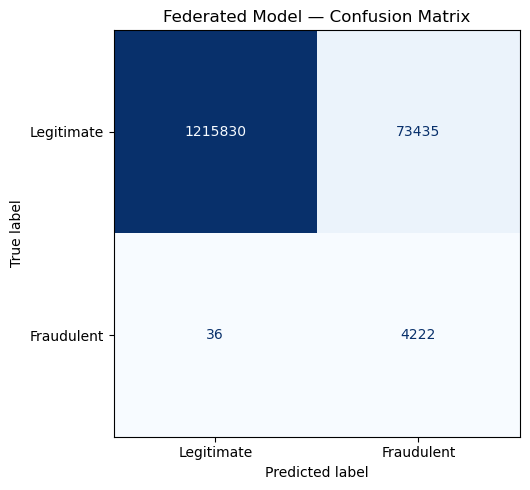

True Negatives: 1,215,830 | False Positives: 73,435
False Negatives: 36 | True Positives: 4,222
Total evaluated: 1,293,523


In [175]:

# Evaluate the federated model using a confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_final, federated_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

# Visualise correct predictions and classification errors
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraudulent"]
)

fig, ax = plt.subplots(figsize=(7, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Federated Model — Confusion Matrix")
plt.tight_layout()
plt.show()

print(f"True Negatives: {tn:,} | False Positives: {fp:,}")
print(f"False Negatives: {fn:,} | True Positives: {tp:,}")
print(f"Total evaluated: {cm.sum():,}")


In [176]:

# Evaluate the federated model on unseen test transactions
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

fed_accuracy = accuracy_score(y_test_final, federated_predictions)
fed_precision = precision_score(y_test_final, federated_predictions, zero_division=0)
fed_recall = recall_score(y_test_final, federated_predictions, zero_division=0)
fed_f1 = f1_score(y_test_final, federated_predictions, zero_division=0)
fed_roc_auc = roc_auc_score(y_test_final, federated_probabilities)
fed_pr_auc = average_precision_score(y_test_final, federated_probabilities)

fed_metrics = pd.DataFrame([{
    "Accuracy": fed_accuracy,
    "Precision": fed_precision,
    "Recall": fed_recall,
    "F1-score": fed_f1,
    "ROC-AUC": fed_roc_auc,
    "PR-AUC": fed_pr_auc
}], index=["Federated MLP"])

display(fed_metrics.round(4))


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Federated MLP,0.9432,0.0544,0.9915,0.1031,0.9954,0.663


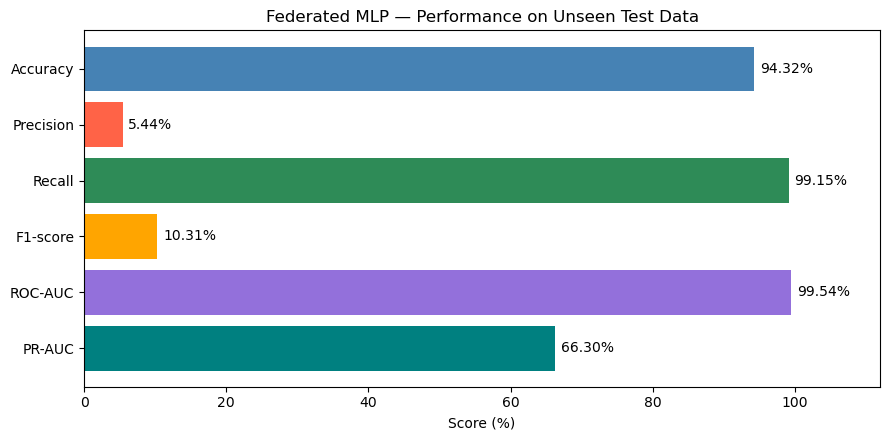

In [177]:

# Visualise the federated model's evaluation results
metrics_to_plot = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC", "PR-AUC"
]

scores = fed_metrics.loc["Federated MLP", metrics_to_plot]

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(
    metrics_to_plot,
    scores.values * 100,
    color=["steelblue", "tomato", "seagreen",
           "orange", "mediumpurple", "teal"]
)

ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set_xlim(0, 112)
ax.set_xlabel("Score (%)")
ax.set_title("Federated MLP — Performance on Unseen Test Data")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


In [178]:

# Generate predictions for the four baseline models
baseline_models = {
    "Bank A": local_model_a,
    "Bank B": local_model_b,
    "Bank C": local_model_c,
    "Centralised": central_model
}

baseline_probabilities = {}

for name, model in baseline_models.items():
    probabilities = predict_fraud(model, X_test_final)

    assert len(probabilities) == len(y_test_final)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    baseline_probabilities[name] = probabilities
    print(f"{name}: {len(probabilities):,} valid predictions")

print("\nAll baseline predictions generated successfully.")


Bank A: 1,293,523 valid predictions
Bank B: 1,293,523 valid predictions
Bank C: 1,293,523 valid predictions
Centralised: 1,293,523 valid predictions

All baseline predictions generated successfully.


In [179]:

# Compare all five models using the same unseen test dataset
evaluation_probabilities = {
    **baseline_probabilities,
    "Federated": federated_probabilities
}

evaluation_results = []

for name, probabilities in evaluation_probabilities.items():
    predictions = (probabilities >= threshold).astype(int)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_final, predictions),
        "Precision": precision_score(y_test_final, predictions, zero_division=0),
        "Recall": recall_score(y_test_final, predictions, zero_division=0),
        "F1-score": f1_score(y_test_final, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_final, probabilities),
        "PR-AUC": average_precision_score(y_test_final, probabilities)
    })

evaluation_df = pd.DataFrame(evaluation_results).set_index("Model")

print("Performance comparison — Held-out test dataset")
display(evaluation_df.round(4))


Performance comparison — Held-out test dataset


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Model,,,,,,
Bank A,0.9544,0.0628,0.9227,0.1177,0.9888,0.5539
Bank B,0.8231,0.0181,0.9894,0.0355,0.9858,0.6028
Bank C,0.9255,0.0402,0.9469,0.0772,0.9871,0.5797
Centralised,0.9227,0.0400,0.9782,0.0769,0.9887,0.5232
Federated,0.9432,0.0544,0.9915,0.1031,0.9954,0.6630


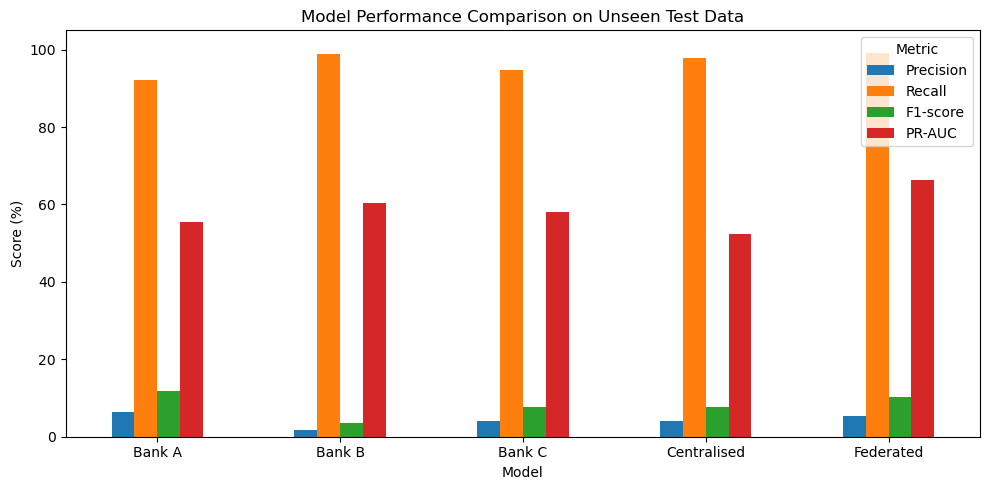

In [181]:
# Visual comparison of all five models
metrics_to_plot = ["Precision", "Recall", "F1-score", "PR-AUC"]

plot_df = evaluation_df[metrics_to_plot] * 100

ax = plot_df.plot(kind="bar", figsize=(10, 5))

ax.set_title("Model Performance Comparison on Unseen Test Data")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Model")
ax.set_ylim(0, 105)
ax.legend(title="Metric")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Confusion Matrix Comparison


,TN,FP,FN,TP
Model,,,,
Bank A,1230663,58602,329,3929
Bank B,1060540,228725,45,4213
Bank C,1193072,96193,226,4032
Centralised,1189403,99862,93,4165
Federated,1215830,73435,36,4222


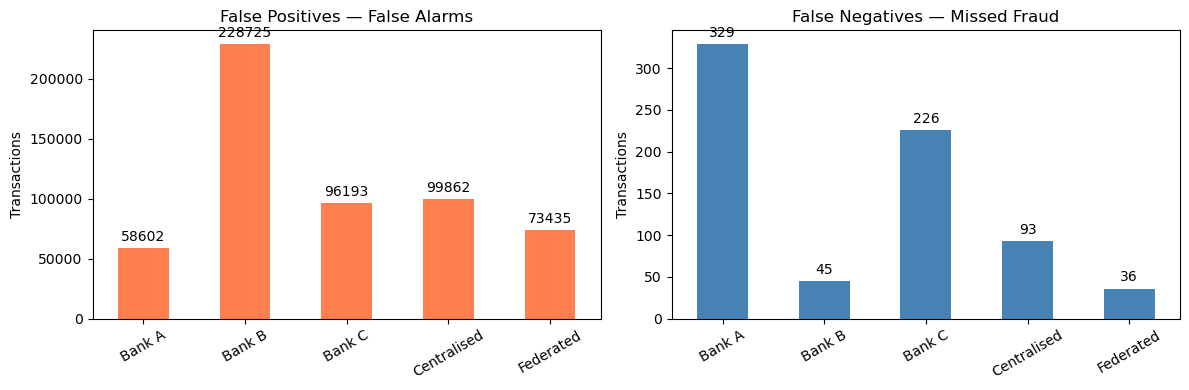

In [182]:

# Compare classification errors across all five models
confusion_results = []

for name, probabilities in evaluation_probabilities.items():
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test_final, predictions, labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "Model": name,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

confusion_df = pd.DataFrame(confusion_results).set_index("Model")

print("Confusion Matrix Comparison")
display(confusion_df)

# Visualise false alarms and missed fraud separately
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

confusion_df["FP"].plot.bar(ax=axes[0], color="coral")
axes[0].set_title("False Positives — False Alarms")
axes[0].set_ylabel("Transactions")

confusion_df["FN"].plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("False Negatives — Missed Fraud")
axes[1].set_ylabel("Transactions")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.bar_label(ax.containers[0], padding=3)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()


In [183]:

# Select a balanced sample of unseen transactions for SHAP
rng = np.random.default_rng(42)

legitimate_indices = rng.choice(
    np.where(y_test_final == 0)[0], size=50, replace=False
)
fraud_indices = rng.choice(
    np.where(y_test_final == 1)[0], size=50, replace=False
)

shap_indices = np.concatenate([legitimate_indices, fraud_indices])
rng.shuffle(shap_indices)

X_shap = X_test_final[shap_indices]
y_shap = y_test_final[shap_indices]

print("SHAP sample prepared:", X_shap.shape)
print("Legitimate:", int((y_shap == 0).sum()))
print("Fraudulent:", int((y_shap == 1).sum()))


SHAP sample prepared: (100, 9)
Legitimate: 50
Fraudulent: 50


In [184]:

# Select training records to serve as SHAP background data
background_rng = np.random.default_rng(42)

background_indices = background_rng.choice(
    len(X_central), size=20, replace=False
)

X_background = X_central[background_indices]
feature_names = MODEL_INPUT_COLUMNS

assert X_background.shape == (20, 9)
assert np.isfinite(X_background).all()
assert len(feature_names) == X_background.shape[1]

print("SHAP background prepared successfully.")
print("Background shape:", X_background.shape)
print("Selected explanation sample:", X_shap.shape)
print("Features:", feature_names)


SHAP background prepared successfully.
Background shape: (20, 9)
Selected explanation sample: (100, 9)
Features: ['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [185]:

# Initialise SHAP for the trained federated model
global_model.eval()

X_explain = X_shap[:10]

explainer = shap.DeepExplainer(
    global_model,
    torch.from_numpy(X_background)
)

print("SHAP explainer initialised successfully.")
print("Background records:", len(X_background))
print("Transactions to explain:", len(X_explain))


SHAP explainer initialised successfully.
Background records: 20
Transactions to explain: 10


In [186]:

# Generate SHAP values for 10 transactions
shap_values = explainer.shap_values(
    torch.from_numpy(X_explain)
)

values = np.asarray(shap_values).reshape(10, 9)

print("SHAP calculation completed.")
print("Shape:", values.shape)


SHAP calculation completed.
Shape: (10, 9)


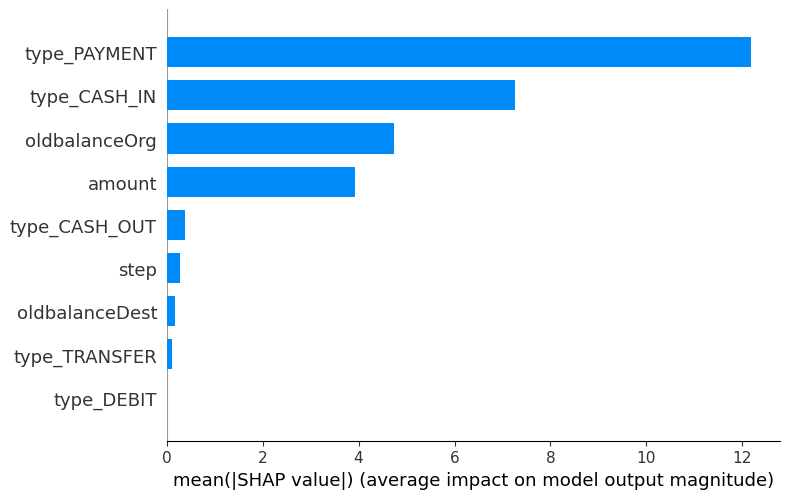

In [188]:
# SHAP feature importance
shap.summary_plot(
    values,
    X_explain,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

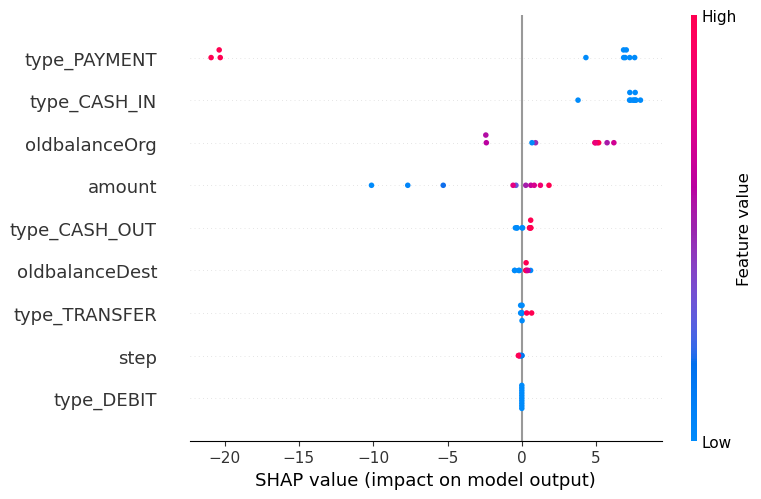

In [87]:

# SHAP summary plot

shap.summary_plot(
    values,
    X_explain,
    feature_names=feature_names
)


## Phase 6: Conclusion

This project investigated federated learning for financial fraud detection using three simulated financial institutions and the PaySim dataset.

Five models were evaluated: three independent local models, one centralised model, and one federated model trained using weighted Federated Averaging (FedAvg).

The federated model achieved a recall of 99.15%, ROC-AUC of 0.9954, and PR-AUC of 0.6630, demonstrating strong fraud detection capability. However, its precision of 5.44% indicates that a substantial number of legitimate transactions were incorrectly classified as fraudulent.

Among the five models, the federated approach achieved the highest recall and PR-AUC, although Bank A obtained the highest F1-score.

SHAP was successfully implemented to provide explainability for selected predictions. The analysis demonstrates how individual transaction features contribute to the model's output, although the small explanation sample limits broader conclusions about feature importance.

Overall, the experiment demonstrates that federated learning can support collaborative fraud detection without centrally pooling raw training records. However, this simulated implementation does not guarantee complete privacy, since model updates may still expose information. Further improvements should investigate threshold optimisation, reducing false positives, and stronger privacy-preserving techniques.